In [1]:
!pip install pandas numpy scikit-learn lightgbm datasets pyarrow shap joblib xgboost imbalanced-learn seaborn matplotlib shap

In [2]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from collections import Counter
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

from imblearn.over_sampling import SMOTE

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.utils.class_weight import compute_class_weight

In [3]:
print("Loading dataset...")

dataset = load_dataset("bvsam/cic-ids-2017", "machine_learning", split="train")
df = dataset.to_pandas()

print("Shape:", df.shape)

Loading dataset...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

machine_learning/Friday-WorkingHours-Aft(…):   0%|          | 0.00/22.2M [00:00<?, ?B/s]

machine_learning/Friday-WorkingHours-Aft(…):   0%|          | 0.00/15.7M [00:00<?, ?B/s]

machine_learning/Friday-WorkingHours-Mor(…):   0%|          | 0.00/19.4M [00:00<?, ?B/s]

... (3 outputs left out)

machine_learning/Tuesday-WorkingHours.pc(…):   0%|          | 0.00/45.6M [00:00<?, ?B/s]

machine_learning/Wednesday-workingHours.(…):   0%|          | 0.00/67.4M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2830743 [00:00<?, ? examples/s]

Shape: (2830743, 79)


In [4]:
print("Shape:", df.shape)
print(df["Label"].value_counts())

Shape: (2830743, 79)
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [5]:
X = df.drop(columns=["Label"])
y = df["Label"]

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [7]:
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

In [8]:
print("Before SMOTE:", Counter(y_train_enc))

Before SMOTE: Counter({np.int64(0): 1818477, np.int64(4): 184858, np.int64(10): 127144, np.int64(2): 102421, np.int64(3): 8234, np.int64(7): 6350, np.int64(11): 4718, np.int64(6): 4637, np.int64(5): 4399, np.int64(1): 1573, np.int64(12): 1206, np.int64(14): 522, np.int64(9): 29, np.int64(13): 17, np.int64(8): 9})


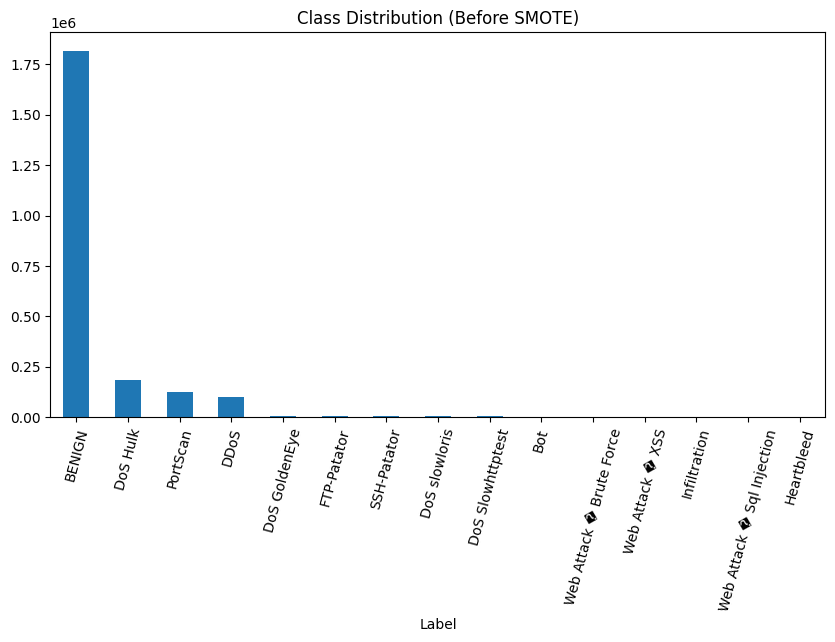

In [9]:
plt.figure(figsize=(10,5))
pd.Series(y_train).value_counts().plot(kind="bar")
plt.title("Class Distribution (Before SMOTE)")
plt.xticks(rotation=75)
plt.show()

In [10]:
smote = SMOTE(
    sampling_strategy="not majority",
    k_neighbors=3,
    random_state=42
)

X_res, y_res = smote.fit_resample(X_train, y_train_enc)

In [11]:
print("After SMOTE:", Counter(y_res))

After SMOTE: Counter({np.int64(4): 1818477, np.int64(0): 1818477, np.int64(1): 1818477, np.int64(2): 1818477, np.int64(10): 1818477, np.int64(7): 1818477, np.int64(11): 1818477, np.int64(3): 1818477, np.int64(5): 1818477, np.int64(12): 1818477, np.int64(6): 1818477, np.int64(14): 1818477, np.int64(9): 1818477, np.int64(13): 1818477, np.int64(8): 1818477})


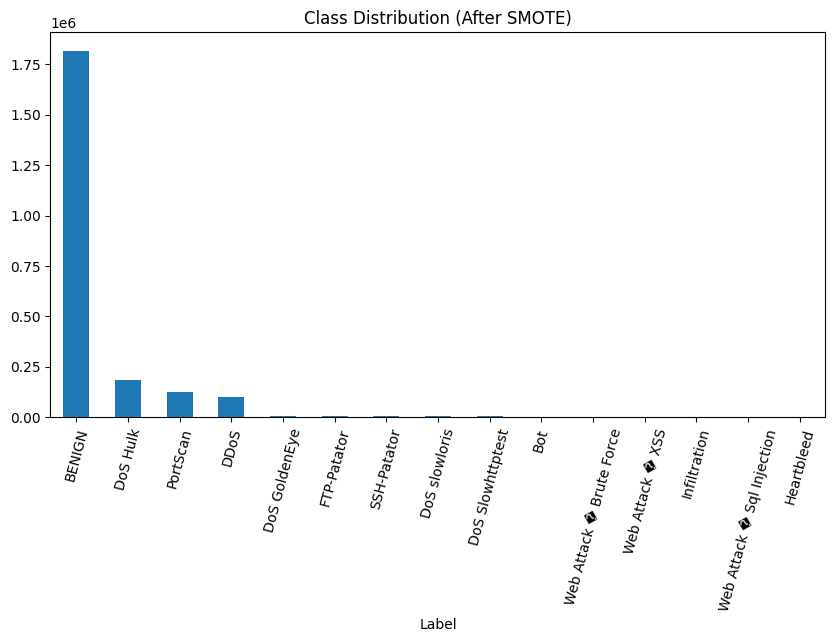

In [12]:
plt.figure(figsize=(10,5))
pd.Series(y_train).value_counts().plot(kind="bar")
plt.title("Class Distribution (After SMOTE)")
plt.xticks(rotation=75)
plt.show()

In [13]:
joblib.dump(X_res, "X_res.pkl")
joblib.dump(y_res, "y_res.pkl")

['y_res.pkl']

In [14]:
models = {
    "RandomForest": RandomForestClassifier(
        n_estimators=80,
        max_depth=15,
        n_jobs=-1,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=120,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="mlogloss",
        tree_method="hist",
        device="cuda",
        n_jobs=-1,
        random_state=42
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=120,
        learning_rate=0.05,
        num_leaves=31,
        random_state=42
    )
}

In [15]:
results = []
predictions = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_res, y_res)

    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    report = classification_report(
        y_test_enc,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    print(f"\n=== {name} ===")
    print(classification_report(y_test_enc, y_pred, target_names=le.classes_))

    results.append({
        "Model": name,
        "Accuracy": report["accuracy"],
        "Precision": report["macro avg"]["precision"],
        "Recall": report["macro avg"]["recall"],
        "F1-score": report["macro avg"]["f1-score"]
    })


Training RandomForest...

=== RandomForest ===
                            precision    recall  f1-score   support

                    BENIGN       1.00      0.99      0.99    454620
                       Bot       0.10      1.00      0.18       393
                      DDoS       1.00      1.00      1.00     25606
             DoS GoldenEye       0.97      1.00      0.99      2059
                  DoS Hulk       0.98      1.00      0.99     46215
          DoS Slowhttptest       0.96      0.99      0.98      1100
             DoS slowloris       0.99      0.99      0.99      1159
               FTP-Patator       1.00      1.00      1.00      1588
                Heartbleed       1.00      1.00      1.00         2
              Infiltration       0.86      0.86      0.86         7
                  PortScan       0.99      1.00      1.00     31786
               SSH-Patator       1.00      1.00      1.00      1179
  Web Attack � Brute Force       0.48      0.55      0.51       301

/usr/local/lib/python3.12/dist-packages/xgboost/core.py:751: UserWarning: [11:56:35] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)



=== XGBoost ===
                            precision    recall  f1-score   support

                    BENIGN       1.00      1.00      1.00    454620
                       Bot       0.37      1.00      0.54       393
                      DDoS       1.00      1.00      1.00     25606
             DoS GoldenEye       0.98      1.00      0.99      2059
                  DoS Hulk       1.00      1.00      1.00     46215
          DoS Slowhttptest       0.97      0.99      0.98      1100
             DoS slowloris       0.98      1.00      0.99      1159
               FTP-Patator       1.00      1.00      1.00      1588
                Heartbleed       1.00      1.00      1.00         2
              Infiltration       1.00      1.00      1.00         7
                  PortScan       0.99      1.00      1.00     31786
               SSH-Patator       1.00      1.00      1.00      1179
  Web Attack � Brute Force       0.74      0.65      0.69       301
Web Attack � Sql Injection    

In [16]:
joblib.dump(predictions, "predictions.pkl")
joblib.dump(results, "results.pkl")

['results.pkl']

In [17]:
os.makedirs("models", exist_ok=True)

for name, model in models.items():
    joblib.dump(model, f"models/{name}.pkl")

joblib.dump(le, "models/label_encoder.pkl")

['models/label_encoder.pkl']

In [18]:
os.makedirs("data", exist_ok=True)

with open("data/feature_columns.json", "w") as f:
    json.dump(X_train.columns.tolist(), f)

In [19]:
def plot_confusion_matrix(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred)

    fig = px.imshow(
        cm,
        text_auto=True,
        x=labels,
        y=labels,
        color_continuous_scale="Blues",
        title=title
    )

    fig.update_layout(
        xaxis_title="Predicted",
        yaxis_title="Actual"
    )

    fig.show()

In [20]:
for name, y_pred in predictions.items():
    plot_confusion_matrix(
        y_test_enc,
        y_pred,
        labels=le.classes_,
        title=f"Confusion Matrix - {name}"
    )

In [21]:
df_results = pd.DataFrame(results)

df_melt = df_results.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

fig = px.bar(
    df_melt,
    x="Model",
    y="Score",
    color="Metric",
    barmode="group",
    text_auto=".3f",
    title="Model Comparison"
)

fig.show()

In [22]:
df_results = pd.DataFrame(results)
df_results = df_results.round(3)
df_results.style.highlight_max(axis=0, color='lightgreen')

,Model,Accuracy,Precision,Recall,F1-score
0,RandomForest,0.990000,0.777000,0.908000,0.800000
1,XGBoost,0.998000,0.851000,0.955000,0.880000
2,LightGBM,0.998000,0.878000,0.953000,0.905000


In [23]:
df_results.to_csv("model_results.csv", index=False)